<a href="https://colab.research.google.com/github/meghaVineeth/GoogleColabs/blob/financialAnalytics/Bank_FD_PredModel_Linear_Reg_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
## This is my first Python code, although it is a copy of what KVK sir is teaching

import pandas as pd                 ## For handling the data in python
import numpy as np                  ## For math calculations
import matplotlib.pyplot as plt     ## For plotting graphs

from sklearn.model_selection import train_test_split    ## Splitting the data into training and testing data
from sklearn.linear_model import LinearRegression    ## for defining the model as linear regression
from sklearn.metrics import r2_score    ## for evaluating model accuracy

import seaborn as sns ## for plotting related graphs

import warnings
warnings.filterwarnings("ignore")

In [2]:
## Step 1: Load the data
df = pd.read_csv("/content/drive/MyDrive/FA/Predictive Analysis/bank_fd_data.csv")

In [10]:
## Step 2: Data processing
# df.head()
# df.tail()
df.isnull().sum()

,0
Account_Name,0
Account_Age_Months,0
Fixed_Deposit_USD,0
Interest_Rate_%,0
Account_Balance_USD,0


In [11]:
## Step 2: Data processing (1 - Treatment of missing values)
## Account_Age_Months	to be filled with mean value
## Fixed_Deposit_USD	to be filled with previous value
df['Account_Age_Months'] = df['Account_Age_Months'].fillna(df['Account_Age_Months'].mean())
df['Fixed_Deposit_USD'] = df['Fixed_Deposit_USD'].ffill()
df.isnull().sum()

,0
Account_Name,0
Account_Age_Months,0
Fixed_Deposit_USD,0
Interest_Rate_%,0
Account_Balance_USD,0


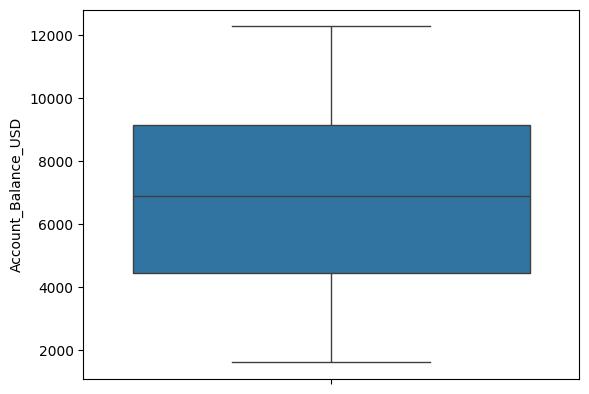

In [19]:
## Step 2: Data processing - Handle outliers (2 - Exploratory data analysis)
sns.boxplot(data=df['Account_Balance_USD']) ## creates box plot to see outliers
plt.show()                                  ## Displays plot
## Look for dots outside the boxes to see if there are any outliers

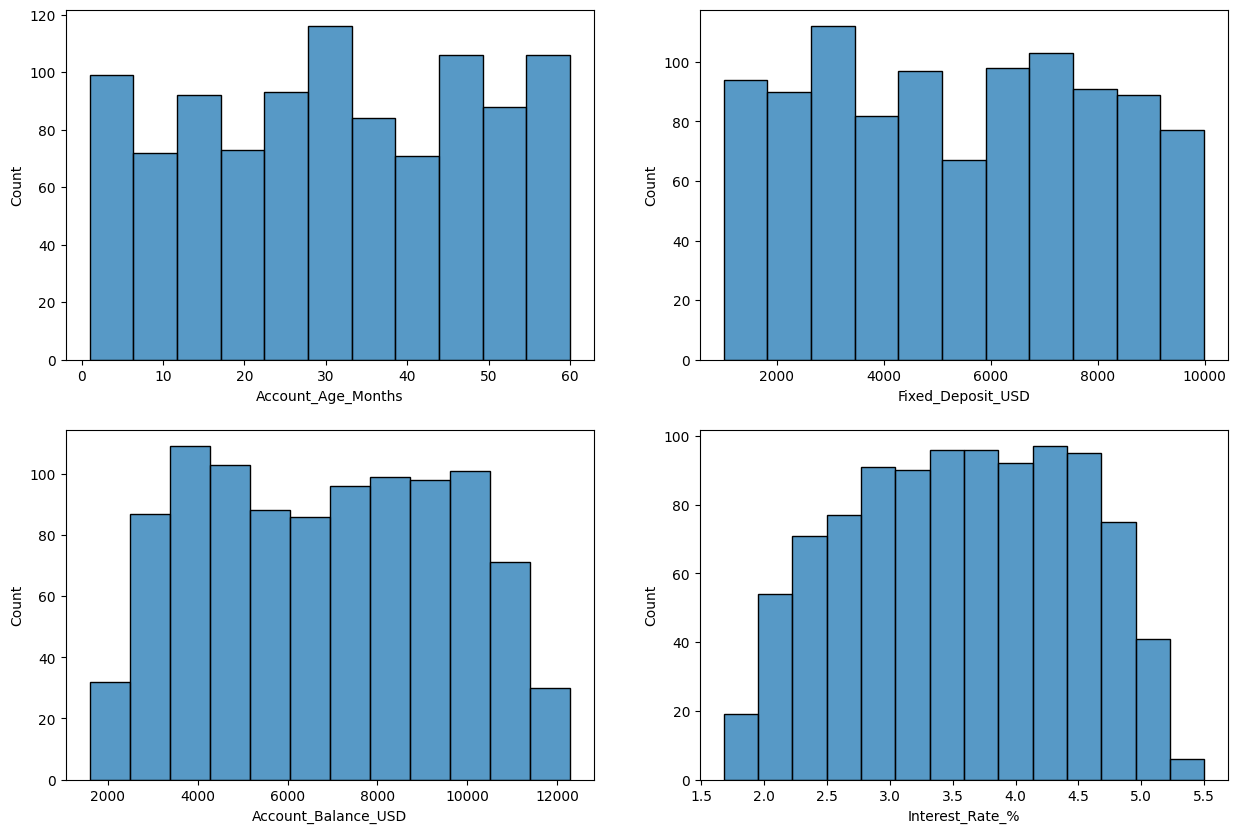

In [21]:
## Step 2: Data processing (3 - Normality of the data (Exploratory analysis))
plt.figure(figsize=(15,10))
for i, column in enumerate(['Account_Age_Months','Fixed_Deposit_USD','Account_Balance_USD','Interest_Rate_%']):
  plt.subplot(2,2,i+1)
  sns.histplot(data = df, x = column)
plt.show()
## Usually - for linear reg we need the data to be normally distributed, transform the data into other forms (log, exp) or scale the data and then process it

In [27]:
##Step 3: define X & Y (X independent, Y dependent)
X = df[['Account_Age_Months','Account_Balance_USD','Interest_Rate_%']]
Y = df['Fixed_Deposit_USD']

In [33]:
## Step 4: Split into training and test set
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
X.shape, X_train.shape, X_test.shape, Y.shape, Y_train.shape, Y_test.shape

((1000, 3), (800, 3), (200, 3), (1000,), (800,), (200,))

In [34]:
## Step 5: Define the model to be used (Linear, logistic, Decision tree etc)
model = LinearRegression()

In [36]:
## Step 6: Fit the model using taining data/Estimate paramenter alpha and beta/ build the model ( ya= a+ bx)
model.fit(X_train, Y_train)
model.coef_, model.intercept_

(array([ -0.34825304,   0.93424605, -51.80795183]),
 np.float64(-792.2154145456616))

In [40]:
## Step 7: Make predictions for test data
Y_pred = model.predict(X_test)  ## 200 predictions using test data
# Y_pred

In [ ]:
## Step 8: Evaluate the model (using rsquare and confusion matrix)
